In [13]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


[autoreload of chromadb_rust_bindings failed: Traceback (most recent call last):
  File "/Users/kasparbeelen/anaconda3/envs/hw/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
  File "/Users/kasparbeelen/anaconda3/envs/hw/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 580, in superreload
    module = reload(module)
             ^^^^^^^^^^^^^^
  File "/Users/kasparbeelen/anaconda3/envs/hw/lib/python3.12/importlib/__init__.py", line 131, in reload
    _bootstrap._exec(spec, module)
  File "<frozen importlib._bootstrap>", line 866, in _exec
  File "<frozen importlib._bootstrap_external>", line 999, in exec_module
  File "<frozen importlib._bootstrap>", line 488, in _call_with_frames_removed
  File "/Users/kasparbeelen/anaconda3/envs/hw/lib/python3.12/site-packages/chromadb_rust_bindings/__init__.py", line 3, in <module>
    __doc__ = chromadb_rust_bindings.__doc__
              ^^^^^^^^^^^

In [14]:
#import torch

In [15]:
#import transformers
#transformers.__version__

In [ ]:
from huggingface_hub import notebook_login


In [17]:
notebook_login()

In [18]:
from transformers import AutoProcessor, AutoModel


In [19]:
model = AutoModel.from_pretrained("google/siglip-base-patch16-224")
processor = AutoProcessor.from_pretrained("google/siglip-base-patch16-224")

In [20]:
import chromadb
import json
import pandas as pd
import matplotlib.pyplot as plt
#from chromadb.utils.data_loaders import ImageLoader
from weavingtools.embedding_tools import SigLIPEmbedder, ImageLoaderRGB
from weavingtools.linkage_tools import plot_query_results
import scipy.spatial as sp
import seaborn as sns
import numpy as np
sns.set()

In [21]:
checkpoint = 'google/siglip-base-patch16-224' #'Kaspar/siglip-heritage-weaver-text-best'# '' | 'Kaspar/siglip-heritage-weaver-text-best

siglip_embedder = SigLIPEmbedder(checkpoint)

client = chromadb.PersistentClient(path="hw-10-25")

data_loader = ImageLoaderRGB()


collection_db = client.get_or_create_collection(name='heritage-weaver-base',#-ft-best  
                                             metadata={"hnsw:space": "cosine"},
                                             embedding_function=siglip_embedder, 
                                             data_loader=data_loader
                                            )

# Check database

In [22]:
collection_df = pd.read_csv('data/heritage_weaver_data.csv')
collection_df.shape

(31319, 12)

In [23]:
len(collection_df.record_id.unique())

21871

In [53]:
from weavingtools.embedding_tools import load_db
collection_db_ft_best = load_db("hw-10-25",'heritage-weaver-ft-best','Kaspar/siglip-heritage-weaver-best')

In [54]:
collection_db.count()

108876

In [55]:
collection_df.shape[0]
collection_db.count()
collection_db_ft_best.count()

108876

# Compare a pair of items across modalities

In [56]:
data = collection_db.get()# where={'collection':'smg'}


In [57]:
res = collection_db.get(where={'record_id':'co20427'},include=['embeddings','metadatas','documents'])
# T.2010.54.1 co22633
res.keys()

dict_keys(['ids', 'embeddings', 'documents', 'uris', 'included', 'data', 'metadatas'])

In [58]:
for i in res['metadatas']:
    print(i)

{'name': 'specimen', 'img_path': 'smg_imgs/390|392|medium_SMG00088115.jpg', 'modality': 'image', 'collection': 'smg', 'record_id': 'co20427', 'img_url': 'https://coimages.sciencemuseumgroup.org.uk/390/392/medium_smg00088115.jpg'}
{'collection': 'smg', 'modality': 'text', 'img_url': 'https://coimages.sciencemuseumgroup.org.uk/390/392/medium_smg00088115.jpg', 'sentence': 'specimen', 'name': 'specimen', 'img_path': 'smg_imgs/390|392|medium_SMG00088115.jpg', 'record_id': 'co20427'}
{'record_id': 'co20427', 'img_url': 'https://coimages.sciencemuseumgroup.org.uk/390/392/medium_smg00088115.jpg', 'sentence': 'No.', 'modality': 'text', 'name': 'specimen', 'collection': 'smg', 'img_path': 'smg_imgs/390|392|medium_SMG00088115.jpg'}
{'collection': 'smg', 'name': 'specimen', 'modality': 'text', 'record_id': 'co20427', 'img_path': 'smg_imgs/390|392|medium_SMG00088115.jpg', 'img_url': 'https://coimages.sciencemuseumgroup.org.uk/390/392/medium_smg00088115.jpg', 'sentence': '2 Glamorgan coke.'}
{'modal

In [59]:
#idx1, idx2 = 100, 8003

In [60]:
rids = [record['record_id'] for record in data['metadatas']]
ids = data['ids']
r1 = collection_db.get(where={'record_id':'co20427'},include=['embeddings','metadatas'])
r2 = collection_db.get(where={'record_id':'T.2019.143'},include=['embeddings','metadatas'])
im_1 = [r['modality'] for r in r1['metadatas']]
im_2 = [r['modality'] for r in r2['metadatas']]
sent_1 = [r.get('sentence','image') for r in r1['metadatas']]
sent_2 = [r.get('sentence','image') for r in r2['metadatas']]
r1_emb = np.matrix(r1['embeddings'])
r2_emb = np.matrix(r2['embeddings'])
mult = 1 - sp.distance.cdist(r1_emb,r2_emb, 'cosine')

In [61]:
similiarities = list(zip(*np.where(mult > 0.8)))
[(sent_1[i], sent_2[j], mult[i,j]) for i,j in similiarities]

[]

In [62]:
mult

array([[ 0.49195187,  0.5275205 , -0.0133849 ,  0.00111035],
       [ 0.01857773,  0.02256434,  0.76611414,  0.27484214],
       [-0.0527621 , -0.06255958,  0.71525543,  0.2573589 ],
       [ 0.00603704,  0.00972709,  0.67277864,  0.25083258],
       [-0.0527621 , -0.06255958,  0.71525543,  0.2573589 ],
       [ 0.00603704,  0.00972709,  0.67277864,  0.25083258]])

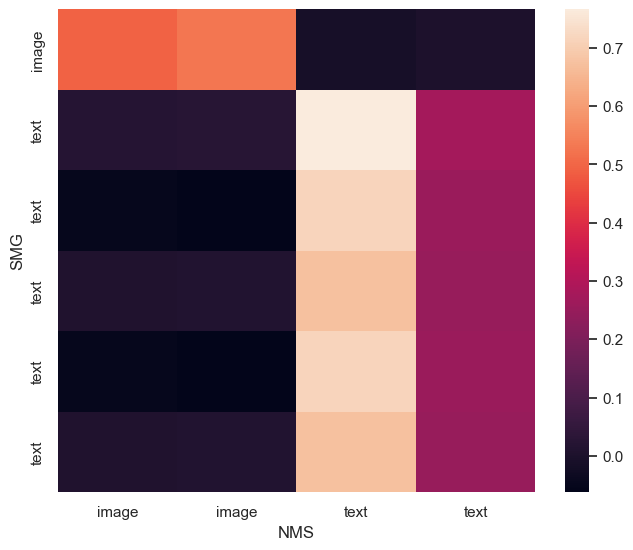

In [63]:
sns.set(rc={'figure.figsize':(7.7,6.27)})
ax = sns.heatmap(mult, yticklabels=im_1, xticklabels=im_2)
ax.set(xlabel='NMS', ylabel='SMG')
plt.show()
fig = ax.get_figure()
fig.savefig("figures/figure_8.png", bbox_inches='tight', dpi=1000)

# Collection Level Comparison

In [64]:
from weavingtools.linkage_tools import compute_similarities, get_edges, get_data
from weavingtools.annotation_tools import *
from weavingtools.embedding_tools import *
from tqdm.notebook import tqdm
import networkx as nx

In [65]:
def plot_record_pairs(record_pairs):
    fig, axes = plt.subplots(len(record_pairs), 2, figsize=(15, 15.5))
    
    for j in range(len(record_pairs)):
        for i in range(2):
            record = collection_df[collection_df.record_id==record_pairs[j][i]]
            img_path = record.img_path.values[0]
            description = soft_wrap_text( record.description.values[0]) # record.record_id.values[0] + ' '  +
            img = Image.open(img_path)
            axes[j,i].imshow(img)
            #axes[j,i].set_title(record.record_id.values[0], fontsize = 10)
            axes[j,i].set_title(description[:50], fontsize = 10)
            axes[j,i].axis('off')
         
    plt.show()



In [66]:
coll1, coll2 = 'smg','nms'
modality1, modality2 = 'text','text' #'image', 'image' #
agg_func = 'max' # mean or max
percentile = 99.9  #99.95 | False
threshold = 0.8
tt_edges, tt_similarities, tt_inputs = get_edges(collection_db,coll1,coll2, modality1, modality2, agg_func, percentile, threshold,); len(tt_edges)


Get inputs...
Compute similarities...
--- Get similarities ---
--- Using 0.8651684986840553 as threshold ---
--- Aggregate similarities by record ---
--- Threshold similarities and binarize ---
Retrieve edges...


137389

In [67]:
coll1, coll2 = 'smg','nms'
modality1, modality2 = 'image','image' #'image', 'image' #
agg_func = 'max' # mean or max
percentile = 99.75  #99.95 | False
threshold = 0.8
ii_edges, ii_similarities, ii_inputs = get_edges(collection_db,coll1,coll2, modality1, modality2, agg_func,percentile, threshold ); len(ii_edges)


Get inputs...
Compute similarities...
--- Get similarities ---
--- Using 0.7970569799827267 as threshold ---
--- Aggregate similarities by record ---
--- Threshold similarities and binarize ---
Retrieve edges...


62623

In [68]:
coll1, coll2 = 'smg','nms'
modality1, modality2 = 'image','text' #'image', 'image' #
agg_func = 'max' # mean or max
percentile = 99.75  #99.95 | False
threshold = 0.8
it_edges, it_similarities, it_inputs = get_edges(collection_db,coll1,coll2, modality1, modality2, agg_func,percentile, threshold ); len(ii_edges)


Get inputs...
Compute similarities...
--- Get similarities ---
--- Using 0.12670584800700158 as threshold ---
--- Aggregate similarities by record ---
--- Threshold similarities and binarize ---
Retrieve edges...


62623

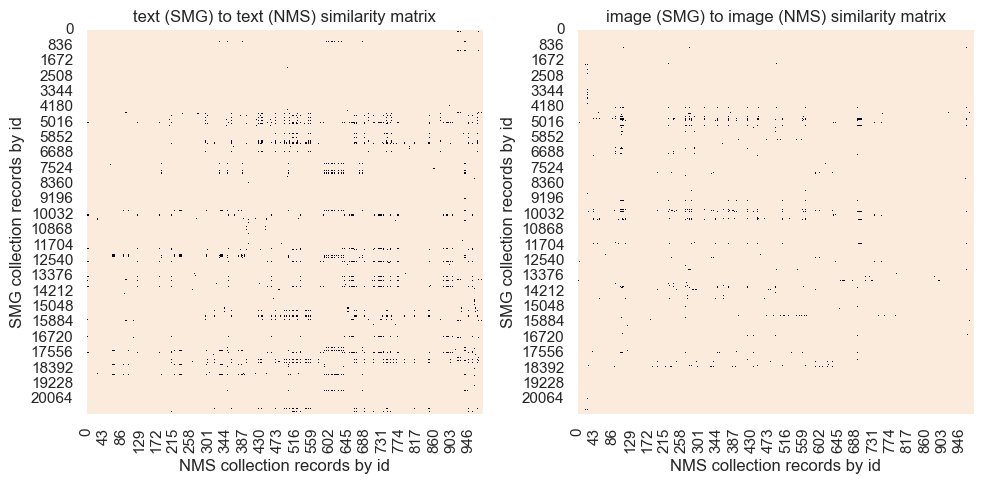

In [69]:
# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

# Plot the first matrix
sns.heatmap(tt_similarities*-1, ax=axs[0], cbar=False) # , annot=True, cbar=False
axs[0].set_title('text (SMG) to text (NMS) similarity matrix')
axs[0].set_xlabel('NMS collection records by id')
axs[0].set_ylabel('SMG collection records by id')

# Plot the second matrix
sns.heatmap(ii_similarities*-1, ax=axs[1], cbar=False) # , annot=True, cbar=False
axs[1].set_title('image (SMG) to image (NMS) similarity matrix')
axs[1].set_xlabel('NMS collection records by id')
axs[1].set_ylabel('SMG collection records by id')

# Adjust the spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()


In [70]:
fig.savefig("figures/figure_9.png", bbox_inches='tight', dpi=1000)

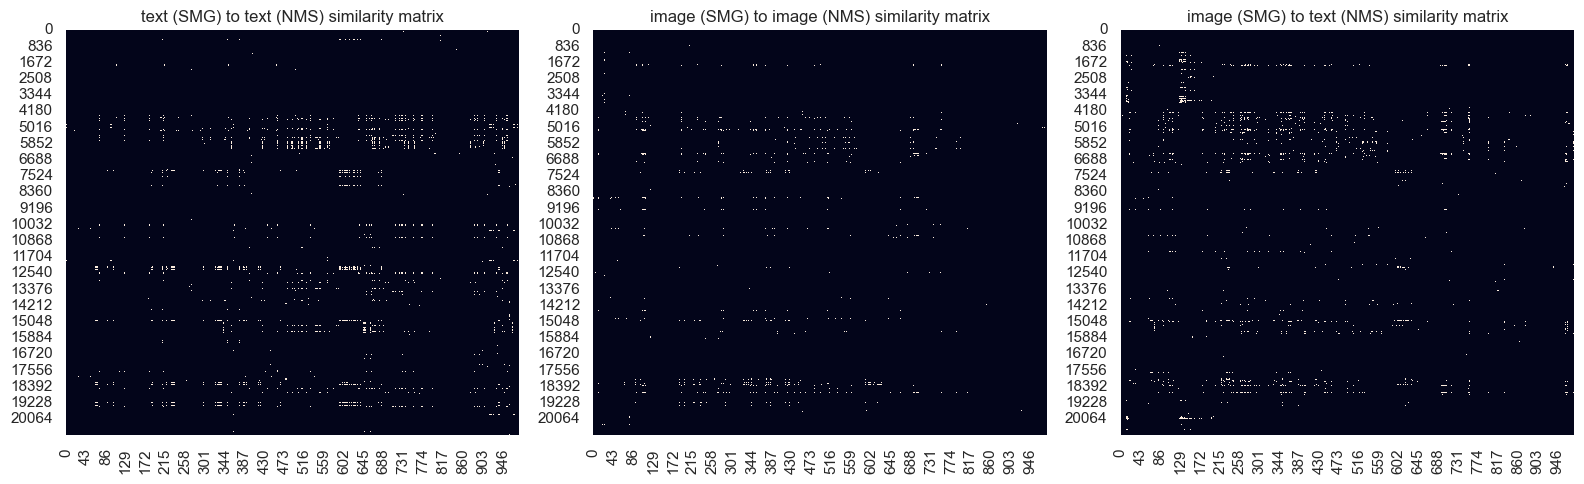

In [71]:
# Create a figure with two subplots
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

# Plot the first matrix
sns.heatmap(tt_similarities, ax=axs[0], cbar=False) # , annot=True, cbar=False
axs[0].set_title('text (SMG) to text (NMS) similarity matrix')

# Plot the second matrix
sns.heatmap(ii_similarities, ax=axs[1], cbar=False) # , annot=True, cbar=False
axs[1].set_title('image (SMG) to image (NMS) similarity matrix')

# Plot the second matrix
sns.heatmap(it_similarities, ax=axs[2], cbar=False)  # , annot=True, cbar=False
axs[2].set_title('image (SMG) to text (NMS) similarity matrix')

# Adjust the spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()


In [72]:
coll1, coll2 = 'smg','nms'
modality1, modality2 = 'text','text' #'image', 'image' #
agg_func = 'max' # mean or max
percentile = 99.9  #99.95 | False
threshold = 0.8
tt_edges_ft_best, tt_similarities_ft_best, tt_inputs_ft_best = get_edges(collection_db_ft_best,coll1,coll2, modality1, modality2, agg_func, percentile, threshold,); len(tt_edges)


Get inputs...
Compute similarities...
--- Get similarities ---
--- Using 0.9173049091786505 as threshold ---
--- Aggregate similarities by record ---
--- Threshold similarities and binarize ---
Retrieve edges...


137389

In [73]:
coll1, coll2 = 'smg','nms'
modality1, modality2 = 'image','image' #'image', 'image' #
agg_func = 'max' # mean or max
percentile = 99.75  #99.95 | False
threshold = 0.8
ii_edges_ft_best, ii_similarities_ft_best, ii_inputs_ft_best = get_edges(collection_db_ft_best,coll1,coll2, modality1, modality2, agg_func,percentile, threshold ); len(ii_edges)


Get inputs...
Compute similarities...
--- Get similarities ---
--- Using 0.8478260873456253 as threshold ---
--- Aggregate similarities by record ---
--- Threshold similarities and binarize ---
Retrieve edges...


62623

In [76]:
coll1, coll2 = 'smg','nms'
modality1, modality2 = 'image','text' #'image', 'image' #
agg_func = 'max' # mean or max
percentile = 99.75  #99.95 | False
threshold = 0.8
it_edges_ft_best, it_similarities_ft_best, it_inputs_ft_best = get_edges(collection_db_ft_best,coll1,coll2, modality1, modality2, agg_func,percentile, threshold ); len(ii_edges)


Get inputs...
Compute similarities...
--- Get similarities ---
--- Using 0.11981853959486555 as threshold ---
--- Aggregate similarities by record ---
--- Threshold similarities and binarize ---
Retrieve edges...


62623

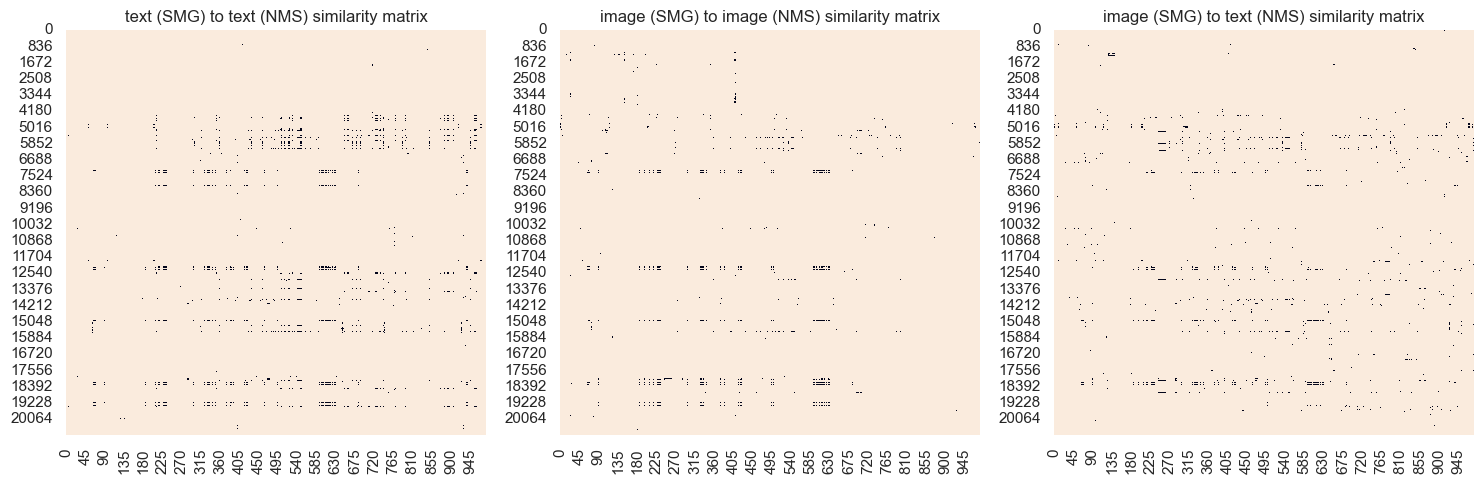

In [80]:
# Create a figure with two subplots
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Plot the first matrix
sns.heatmap(tt_similarities_ft_best*-1, ax=axs[0], cbar=False) # , annot=True, cbar=False
axs[0].set_title('text (SMG) to text (NMS) similarity matrix')

# Plot the second matrix
sns.heatmap(ii_similarities_ft_best*-1, ax=axs[1], cbar=False)  # , annot=True, cbar=False
axs[1].set_title('image (SMG) to image (NMS) similarity matrix')

# Plot the second matrix
sns.heatmap(it_similarities_ft_best*-1, ax=axs[2], cbar=False)  # , annot=True, cbar=False
axs[2].set_title('image (SMG) to text (NMS) similarity matrix')

# Adjust the spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()


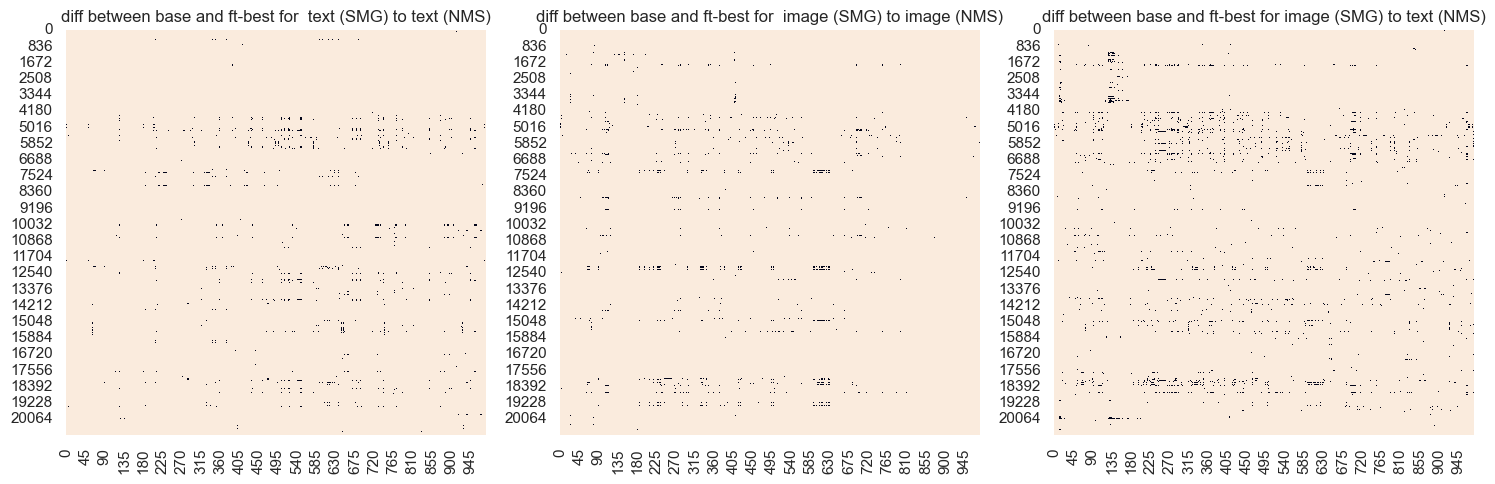

In [81]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Plot the first matrix
sns.heatmap((tt_similarities_ft_best != tt_similarities)*-1, ax=axs[0], cbar=False) # , annot=True, cbar=False
axs[0].set_title('diff between base and ft-best for  text (SMG) to text (NMS)')

# Plot the second matrix
sns.heatmap((ii_similarities_ft_best != ii_similarities)*-1, ax=axs[1], cbar=False)  # , annot=True, cbar=False
axs[1].set_title('diff between base and ft-best for  image (SMG) to image (NMS)')

# Plot the third matrix
sns.heatmap((it_similarities_ft_best != it_similarities)*-1, ax=axs[2], cbar=False) # , annot=True, cbar=False
axs[2].set_title('diff between base and ft-best for image (SMG) to text (NMS)')
# Adjust the spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [ ]:
def overlapping_edges(edges1, edges2):
    return [e for e in edges1 if e in edges2]

overlap = overlapping_edges(tt_edges, ii_edges)

In [ ]:
import random
random.shuffle(overlap)
plot_record_pairs(overlap[:10])

In [ ]:
random.shuffle(ii_edges)
record_pairs = list(ii_edges)[:5]
plot_record_pairs(record_pairs)